In [215]:

import torch
import sys
import numpy as np
import matplotlib.pyplot as plt
from utils import list_files
from pathlib import Path
from plot_anm_score import AnmScoreFigData
from sklearn import metrics
from LD.utils.ld_tools import *
import sys
import os
import copy
from sklearn.cluster import KMeans
from sklearn.metrics import roc_auc_score
import umap
from sklearn.manifold import trustworthiness
from LD.utils.ld_tools import *
import pandas as pd
import plot_anm_score
from sklearn.cluster import DBSCAN
from sklearn.metrics import pairwise_distances


In [216]:
# machine = 'ToyCar'
# machine = 'fan'
machine = 'SliderEmu'

BASEDIR='D:/uni/TER LD/data'

TRAIN_PT_DIR = Path("%s/%s/train"%(BASEDIR, machine))
TEST_PT_DIR = Path("%s/%s/test"%(BASEDIR, machine))


In [217]:
list_train_files = list_files(TRAIN_PT_DIR)
list_test_files = list_files(TEST_PT_DIR)

In [218]:
def load_pt_file(file_path):
    
    relative_path = file_path.relative_to(file_path.parents[2])
    file_name = relative_path.with_suffix(".pt").name
    print(f"file_name: {file_name}")
    data = torch.load(file_path)
    return file_name, data['hidden_states']

In [219]:
f, d = load_pt_file(list_train_files[0])
d.size()

file_name: section_00_source_train_normal_0000_noAttribute.pt


torch.Size([250, 768])

In [220]:
def concatenate_hidden_states(file_paths, reduction='avg'):
    
    output = {'train': {'source': [], 'target': []}, 
              'test': {'source': {'normal': [], 'anomaly': []}, 'target': {'normal': [], 'anomaly': []}}}
    
    for file_path in file_paths:
        file_name, hidden_states = load_pt_file(file_path)
        if reduction == 'avg':
            hidden_states = hidden_states.mean(dim=0, keepdim=True)  # Average over the sequence length dimension
        elif reduction == 'max':
            hidden_states, _ = hidden_states.max(dim=0, keepdim=True)  # Max over the sequence length dimension
        elif reduction == 'std':
            hidden_states = hidden_states.std(dim=0, keepdim=True)  # Std over the sequence length dimension
        # elif reduction == 'none':
        #     hidden_states = hidden_states.unsqueeze(0)  # Add a dummy dimension for concatenation
        print(hidden_states.size())
        # print(file_path)
        if 'train' in file_name:
            if 'source' in file_name:
                output['train']['source'].append(hidden_states)
            elif 'target' in file_name:
                output['train']['target'].append(hidden_states)
        elif 'test' in file_name:
            if 'source' in file_name:
                if 'normal' in file_name:
                    output['test']['source']['normal'].append(hidden_states)
                elif 'anomaly' in file_name:
                    output['test']['source']['anomaly'].append(hidden_states)
            elif 'target' in file_name:
                if 'normal' in file_name:
                    output['test']['target']['normal'].append(hidden_states)
                elif 'anomaly' in file_name:
                    output['test']['target']['anomaly'].append(hidden_states)
    
    # concatenate the lists of tensors into single tensors
    for split in output:
        for category in output[split]:
            if isinstance(output[split][category], dict):
                for subcategory in output[split][category]:
                    output[split][category][subcategory] = torch.cat(output[split][category][subcategory], dim=0)
            else:
                output[split][category] = torch.cat(output[split][category], dim=0)
    return output

In [221]:
avg_states = concatenate_hidden_states(list_train_files + list_test_files, reduction='avg')

file_name: section_00_source_train_normal_0000_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0001_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0002_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0003_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0004_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0005_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0006_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0007_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0008_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0009_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0010_noAttribute.pt
torch.Size([1, 768])
file_name: section_00_source_train_normal_0011_noAttribute.pt
torch.Size([1, 768])
file

In [222]:
for split in avg_states:
        for category in avg_states[split]:
            if isinstance(avg_states[split][category], dict):
                for subcategory in avg_states[split][category]:
                    print(split, category, subcategory, avg_states[split][category][subcategory].size())
            else:
                print(split, category, avg_states[split][category].size())

train source torch.Size([990, 768])
train target torch.Size([10, 768])
test source normal torch.Size([50, 768])
test source anomaly torch.Size([50, 768])
test target normal torch.Size([50, 768])
test target anomaly torch.Size([50, 768])


In [223]:
train_X = torch.cat([avg_states['train']['source'], avg_states['train']['target']], dim=0)
train_y = torch.cat([torch.zeros(avg_states['train']['source'].size(0)), torch.ones(avg_states['train']['target'].size(0))], dim=0)

train_source_X = avg_states['train']['source']
train_target_X = avg_states['train']['target']

train_source_y = torch.zeros(avg_states['train']['source'].size(0))
train_target_y = torch.ones(avg_states['train']['target'].size(0))

test_source_X = torch.cat([avg_states['test']['source']['normal'], avg_states['test']['source']['anomaly']], dim=0)
test_source_y = torch.cat([torch.zeros(avg_states['test']['source']['normal'].size(0)), torch.ones(avg_states['test']['source']['anomaly'].size(0))], dim=0)    

test_target_X = torch.cat([avg_states['test']['target']['normal'], avg_states['test']['target']['anomaly']], dim=0)
test_target_y = torch.cat([torch.zeros(avg_states['test']['target']['normal'].size(0)), torch.ones(avg_states['test']['target']['anomaly'].size(0))], dim=0)

train_X.size(), train_y.size(), train_source_X.size(), train_source_y.size(), train_target_X.size(), train_target_y.size(), test_source_X.size(), test_source_y.size(), test_target_X.size(), test_target_y.size(), torch.mean(train_X, dim=0), torch.std(train_X, dim=0)

(torch.Size([1000, 768]),
 torch.Size([1000]),
 torch.Size([990, 768]),
 torch.Size([990]),
 torch.Size([10, 768]),
 torch.Size([10]),
 torch.Size([100, 768]),
 torch.Size([100]),
 torch.Size([100, 768]),
 torch.Size([100]),
 tensor([ 8.4872e-01,  3.0625e-02,  1.2144e-01,  9.3257e-02, -8.9216e-02,
         -1.1067e-01,  1.8996e-01, -5.2383e-01, -3.1500e-01,  2.6084e-01,
         -2.4849e-01,  4.6763e-01,  3.3326e-02,  1.9630e-02, -3.7852e-01,
          4.0919e-01, -4.5534e-02, -4.6748e-01, -2.8757e-01, -1.6943e-01,
         -9.0092e-02, -1.3428e-01, -1.4943e-01,  1.0648e-01,  2.4526e-01,
         -1.3885e-01,  3.2299e-01,  6.5146e-02, -1.9461e-01, -2.8203e-01,
          7.5153e-02,  9.3616e-02,  1.5897e-01,  8.3362e-02, -7.9552e-02,
          2.6926e-01,  8.5515e-02, -1.7648e-01, -1.8942e-01,  1.7596e-01,
          2.7097e-01,  1.4158e-02, -2.5918e-01,  1.6042e-01,  4.1884e-01,
          5.0619e-01, -3.6142e-01, -2.5048e-02,  2.1879e-01,  1.5693e-01,
         -1.6736e-01,  6.4493e-01, 

In [224]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# 1. Apprend la moyenne/variance sur le Train et applique la transformation

train_source_X_scaled = scaler.fit_transform(train_source_X.numpy())
test_source_X_scaled = scaler.transform(test_source_X.numpy())
train_target_X_scaled = scaler.transform(train_target_X.numpy())
test_target_X_scaled = scaler.transform(test_target_X.numpy())

train_source_X = torch.from_numpy(train_source_X_scaled).float()
test_source_X = torch.from_numpy(test_source_X_scaled).float()
train_target_X = torch.from_numpy(train_target_X_scaled).float()
test_target_X = torch.from_numpy(test_target_X_scaled).float()

train_source_X.size(), test_source_X.size(), torch.mean(train_source_X, dim=0), torch.std(train_source_X, dim=0)

(torch.Size([990, 768]),
 torch.Size([100, 768]),
 tensor([ 9.5367e-08, -4.8165e-09, -1.3968e-08, -1.2041e-08, -4.1422e-08,
         -3.4679e-08, -1.1560e-08, -1.6858e-07, -9.7294e-08,  7.3211e-08,
         -4.9129e-08,  9.6331e-08, -4.8165e-09,  3.8532e-09,  1.2716e-07,
         -6.3097e-08,  7.4656e-09, -4.2867e-08,  2.6973e-08, -9.6331e-09,
          5.7798e-09,  1.2523e-08,  5.2019e-08,  2.9863e-08, -5.3945e-08,
          5.7798e-08, -8.2844e-08,  3.7087e-08,  4.2386e-08,  1.2186e-07,
         -2.2216e-08,  1.6376e-08, -3.5642e-08, -2.8899e-09,  3.4438e-08,
          1.2571e-07,  1.3005e-08,  5.8762e-08, -5.7798e-09, -1.2041e-08,
         -1.1560e-08, -1.3486e-08,  8.0436e-08, -6.6950e-08, -8.0918e-08,
          3.1307e-07,  8.1881e-08, -3.8532e-09, -2.9863e-08,  8.7661e-08,
          6.5505e-08, -1.9073e-07, -3.6606e-08,  6.9358e-08, -2.7936e-08,
          1.1560e-08, -5.7798e-09,  1.7291e-07, -3.2030e-08,  5.7798e-09,
          1.4835e-07,  9.1514e-09, -2.1674e-08,  1.8182e-08,  

In [225]:
# variables
stats = []
alpha2 = 15
dim_reduction = 20

### Application de la LD aux donnees brutes (dim = 768)

In [226]:
points = copy.deepcopy(train_source_X)
dist_mat = distance_matrix(points, points)

fermat_dist_mat = fermat_function(dist_mat, alpha=alpha2)
# fermat_dist_mat = pairwise_distances(points, metric='euclidean')


points_test = copy.deepcopy(test_source_X)

In [227]:
fermat_dist_mat 

array([[0.00000000e+00, 2.10650464e+20, 1.13424371e+20, ...,
        1.15521786e+21, 1.56017649e+19, 2.36588097e+21],
       [2.10650464e+20, 0.00000000e+00, 3.16390389e+20, ...,
        1.25654776e+21, 2.17768059e+20, 2.56804726e+21],
       [1.13424371e+20, 3.16390389e+20, 0.00000000e+00, ...,
        1.26864223e+21, 1.16663039e+20, 2.46696682e+21],
       ...,
       [1.15521786e+21, 1.25654776e+21, 1.26864223e+21, ...,
        0.00000000e+00, 1.17081962e+21, 3.51871685e+21],
       [1.56017649e+19, 2.17768059e+20, 1.16663039e+20, ...,
        1.17081962e+21, 0.00000000e+00, 2.35895800e+21],
       [2.36588097e+21, 2.56804726e+21, 2.46696682e+21, ...,
        3.51871685e+21, 2.35895800e+21, 0.00000000e+00]], shape=(990, 990))

In [228]:
lens_depth_ext_fermat = []
for i in range(points_test.shape[0]):
    dist_array = distance_matrix(points,points_test[i].reshape((1,-1)))
    dist_ext = fermat_function_ext(fermat_dist_mat, dist_array,alpha=alpha2)
    lens_depth_ext_fermat += [lens_depth_ext_function(fermat_dist_mat, dist_ext)]


In [229]:
print(min(lens_depth_ext_fermat), max(lens_depth_ext_fermat))

2.042671405664328e-06 0.853842775581906


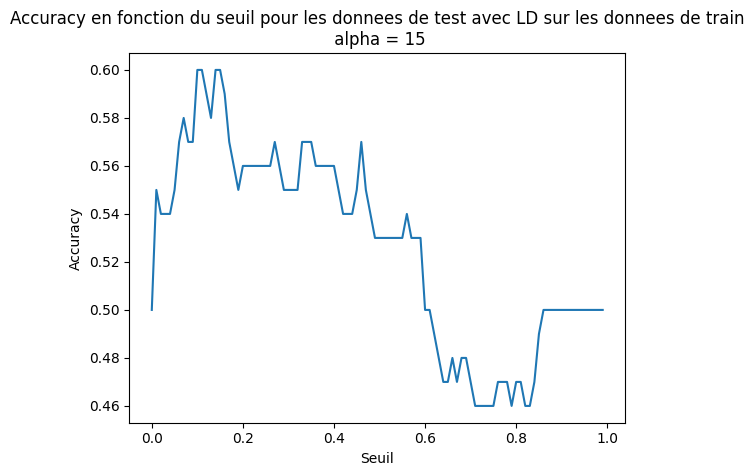

In [230]:
acc_list = []
for i in range(100):
    seuil = i/100
    y_pred = (np.array(lens_depth_ext_fermat) < seuil).astype(int)
    acc_list.append(metrics.accuracy_score(test_source_y.numpy(), y_pred))
    

plt.plot(np.arange(100)/100, acc_list)
plt.xlabel("Seuil")
plt.ylabel("Accuracy")
plt.title(f"Accuracy en fonction du seuil pour les donnees de test avec LD sur les donnees de train\n alpha = {alpha2}")
plt.show()

In [231]:
stats.append(["LD dim=768", alpha2, 1, max(acc_list), np.argmax(acc_list)/100, metrics.roc_auc_score(test_source_y.numpy(), lens_depth_ext_fermat)])

In [232]:
#   A REVOIR LE AUROC

labels_vrais = test_source_y.numpy() 
scores_anomalie = -np.array(lens_depth_ext_fermat)
auroc = roc_auc_score(labels_vrais, scores_anomalie)
print(f"Score AUROC : {auroc}")

Score AUROC : 0.5779999999999998


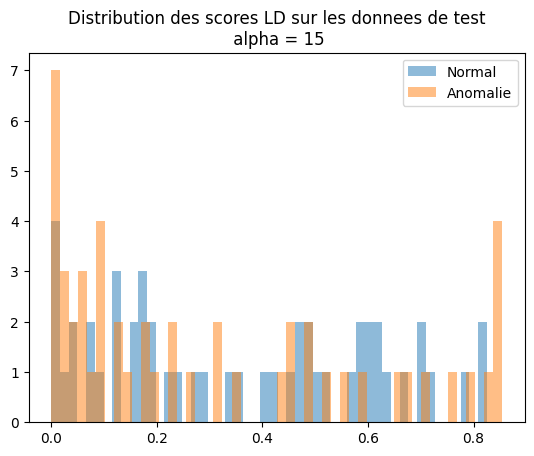

In [233]:
plt.hist(np.array(lens_depth_ext_fermat)[test_source_y == 0], bins=50, alpha=0.5, label='Normal')
plt.hist(np.array(lens_depth_ext_fermat)[test_source_y == 1], bins=50, alpha=0.5, label='Anomalie')
plt.legend()
plt.title(f"Distribution des scores LD sur les donnees de test\n alpha = {alpha2}")
plt.show()

In [234]:
scores_formates = np.column_stack((test_source_y.numpy(), lens_depth_ext_fermat))

visualiseur = AnmScoreFigData()
figdata_run = visualiseur.anm_score_to_figdata(scores_formates, title=(f"Distribution des scores LD dim=768 alpha = {alpha2}"))

visualiseur.append_figdata(figdata_run)
visualiseur.show_fig(title=(f"LD {machine} dim=768 alpha = {alpha2}"), export_dir="resultats")
plt.style.use('default')

export fig -> resultats/LD SliderEmu dim=768 alpha = 15.png


### Test avec reduction UMAP 

In [235]:
train_source_X_copy = copy.deepcopy(train_source_X)

In [236]:
umap_reducer = umap.UMAP(n_components=dim_reduction)
umap_reducer.fit(train_source_X_copy.numpy())
train_source_X_umap = umap_reducer.transform(train_source_X_copy.numpy())
test_source_X_umap = umap_reducer.transform(test_source_X.numpy())

In [237]:
points = copy.deepcopy(train_source_X_umap)
dist_mat = distance_matrix(points, points)
fermat_dist_mat = fermat_function(dist_mat, alpha=alpha2)
# fermat_dist_mat = pairwise_distances(points, metric='correlation')

points_test = copy.deepcopy(test_source_X_umap)

lens_depth_ext_fermat = []
for i in range(points_test.shape[0]):
    dist_array = distance_matrix(points,points_test[i].reshape((1,-1)))
    dist_ext = fermat_function_ext(fermat_dist_mat, dist_array,alpha2)
    lens_depth_ext_fermat += [lens_depth_ext_function(fermat_dist_mat, dist_ext)]

In [238]:
print(test_source_X_umap.shape, test_source_y.shape)

(100, 20) torch.Size([100])


In [239]:
score = trustworthiness(train_source_X.numpy(), train_source_X_umap, n_neighbors=20)
print(f"Trustworthiness score: {score:.4f}")

Trustworthiness score: 0.9739


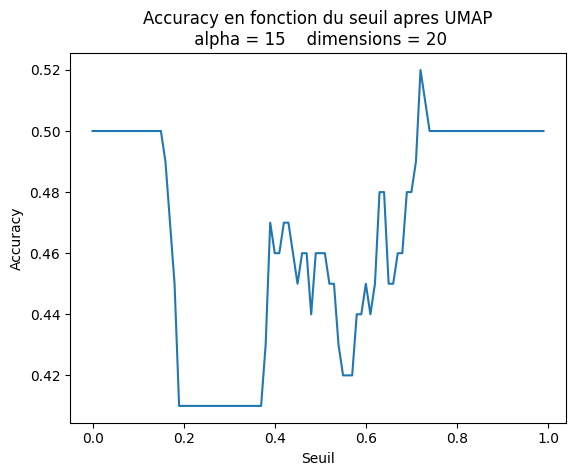

In [240]:
acc_list2 = []
for i in range(100):
    seuil = i/100
    y_pred = (np.array(lens_depth_ext_fermat) < seuil).astype(int)
    acc_list2.append(metrics.accuracy_score(test_source_y.numpy(), y_pred))

plt.plot(np.arange(100)/100, acc_list2)
plt.xlabel("Seuil")
plt.ylabel("Accuracy")
plt.title(f"Accuracy en fonction du seuil apres UMAP\n alpha = {alpha2}    dimensions = {dim_reduction}")
plt.show()

In [241]:
stats.append([(f"LD dim={dim_reduction}"), alpha2, 1, max(acc_list2), np.argmax(acc_list2)/100, metrics.roc_auc_score(test_source_y.numpy(), lens_depth_ext_fermat)])

In [242]:
scores_formates = np.column_stack((test_source_y.numpy(), lens_depth_ext_fermat))

visualiseur = AnmScoreFigData()
figdata_run = visualiseur.anm_score_to_figdata(scores_formates, title=(f"Distribution des scores LD dim={dim_reduction} alpha = {alpha2}"))

visualiseur.append_figdata(figdata_run)
visualiseur.show_fig(title=(f"LD {machine} dim={dim_reduction} alpha = {alpha2}"), export_dir="resultats")
plt.style.use('default')

export fig -> resultats/LD SliderEmu dim=20 alpha = 15.png


### Test avec UMAP + FERMAT

In [243]:
points = copy.deepcopy(train_source_X)
points_test = copy.deepcopy(test_source_X)
dist_mat = distance_matrix(points, points)
# fermat_dist_mat = fermat_function(dist_mat, alpha=alpha2)
fermat_dist_mat = pairwise_distances(points, metric='cosine')

umap_reducer_fermat = umap.UMAP(n_components=dim_reduction, metric='precomputed')
umap_reducer_fermat.fit(fermat_dist_mat)

dist_array_test = distance_matrix(points, points_test)
fermat_dist_mat_test = fermat_function_ext_simultaneous(fermat_dist_mat, dist_array_test.T, alpha=alpha2, device='cpu')

train_source_X_umap_fermat = umap_reducer_fermat.embedding_
test_source_X_umap_fermat = umap_reducer_fermat.transform(fermat_dist_mat_test)

c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
c:\Users\PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:3017: UserWarning: Transforming new data with precomputed metric. We are assuming the input data is a matrix of distances from the new points to the points in the training set. If the input matrix is sparse, it should contain distances from the new points to their nearest neighbours or approximate nearest neighbours in the training set.
  warn(


In [244]:
print(test_source_X.shape, points_test.shape)

torch.Size([100, 768]) torch.Size([100, 768])


In [245]:
points = copy.deepcopy(train_source_X_umap_fermat)
dist_mat = distance_matrix(points, points)
fermat_dist_mat2 = fermat_function(dist_mat, alpha=alpha2)
points_test = copy.deepcopy(test_source_X_umap_fermat)

lens_depth_ext_fermat2 = []
for i in range(points_test.shape[0]):
    dist_array = distance_matrix(points,points_test[i].reshape((1,-1)))
    dist_ext = fermat_function_ext(fermat_dist_mat2, dist_array,alpha2)
    lens_depth_ext_fermat2 += [lens_depth_ext_function(fermat_dist_mat2, dist_ext)]

In [246]:
dist_mat_umap = distance_matrix(train_source_X_umap_fermat, train_source_X_umap_fermat)
fermat_umap = fermat_function(dist_mat_umap, alpha=alpha2)

score = trustworthiness(X= fermat_dist_mat, X_embedded= fermat_umap, n_neighbors=20, metric='precomputed')
print(f"Trustworthiness score: {score:.4f}")

Trustworthiness score: 0.6623


In [247]:
print(min(lens_depth_ext_fermat2), max(lens_depth_ext_fermat2))

0.0 0.6446384982279826


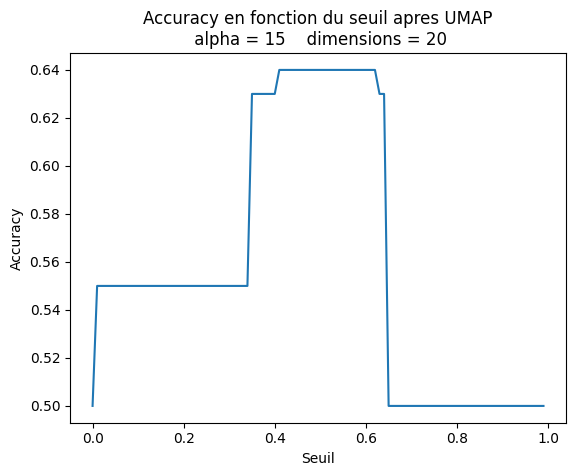

In [248]:
acc_list3 = []
for i in range(100):
    seuil = i/100
    y_pred = (np.array(lens_depth_ext_fermat2) < seuil).astype(int)
    acc_list3.append(metrics.accuracy_score(test_source_y.numpy(), y_pred))
    

plt.plot(np.arange(100)/100, acc_list3)
plt.xlabel("Seuil")
plt.ylabel("Accuracy")
plt.title(f"Accuracy en fonction du seuil apres UMAP\n alpha = {alpha2}    dimensions = {dim_reduction}")
plt.show()

In [249]:
stats.append([(f"LD dim={dim_reduction} + Fermat"), alpha2, 1, max(acc_list3), np.argmax(acc_list3)/100, metrics.roc_auc_score(test_source_y.numpy(), lens_depth_ext_fermat2)])

In [250]:
scores_formates = np.column_stack((test_source_y.numpy(), lens_depth_ext_fermat))

visualiseur = AnmScoreFigData()
figdata_run = visualiseur.anm_score_to_figdata(scores_formates, title=(f"Distribution des scores LD dim={dim_reduction} + fermat alpha = {alpha2}"))

visualiseur.append_figdata(figdata_run)
visualiseur.show_fig(title=(f"LD dim={dim_reduction} + fermat alpha = {alpha2}"), export_dir="resultats")
plt.style.use('default')

export fig -> resultats/LD dim=20 + fermat alpha = 15.png


### Test avec multi-clusters

In [251]:
clust = DBSCAN(eps=10, min_samples=3).fit(points)
clust.labels_

array([0, 0, 0, 0, 0, 0, 0, 1, 2, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0,
       2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 1, 1, 0, 2, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 1,
       1, 0, 0, 0, 2, 0, 2, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 2, 1, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 0, 1, 0, 0,
       2, 2, 0, 0, 0, 0, 2, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 2, 1, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 2, 1, 1, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 2,
       0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       2, 0, 2, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 2,
       0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0,

In [252]:
labels = clust.labels_
valeurs_uniques, comptes = np.unique(labels, return_counts=True)
valeurs_uniques, comptes
# -1 c'est les valeurs considerees comme bruit

(array([0, 1, 2]), array([807,  95,  88]))

In [253]:
list_clusters = []
for i in range(len(valeurs_uniques)):
    if valeurs_uniques[i] != -1: 
        cluster_points = points[labels == valeurs_uniques[i]]
        list_clusters.append(cluster_points)

In [254]:
list_lens_depth_ext_fermat = []
for j in range(len(list_clusters)):
    dist_mat = distance_matrix(list_clusters[j],list_clusters[j])
    fermat_dist_mat = fermat_function(dist_mat,alpha=3)
    lens_depth_ext_fermat = []
    for i in range(points_test.shape[0]):
        dist_array = distance_matrix(list_clusters[j],points_test[i].reshape((1,-1)))
        dist_ext = fermat_function_ext(fermat_dist_mat, dist_array, alpha=alpha2)
        lens_depth_ext_fermat += [lens_depth_ext_function(fermat_dist_mat, dist_ext)]
    list_lens_depth_ext_fermat += [np.array(lens_depth_ext_fermat)]
    
list_lens_depth_ext_fermat = np.array(list_lens_depth_ext_fermat)
lens_depth_ext_fermat_seperate = np.max(list_lens_depth_ext_fermat, axis=0)

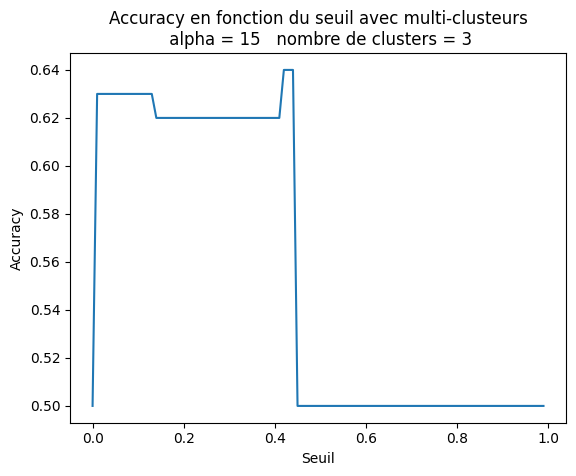

In [255]:
acc_list4 = []
for i in range(100):
    seuil = i/100
    y_pred = (np.array(lens_depth_ext_fermat_seperate) < seuil).astype(int)
    acc_list4.append(metrics.accuracy_score(test_source_y.numpy(), y_pred))
    

plt.plot(np.arange(100)/100, acc_list4)
plt.xlabel("Seuil")
plt.ylabel("Accuracy")
plt.title(f"Accuracy en fonction du seuil avec multi-clusteurs\n alpha = {alpha2}   nombre de clusters = {len(list_clusters)}")
plt.show()

## Resultats:

In [256]:
print("Methode            |  Accuracy maximale    |  Seuil optimal")
print("----------------------------------------------------------------")
print(f"LD dim=768         |  {max(acc_list):.4f}               |  {(np.argmax(acc_list)/100):.2f}")
print(f"LD dim={dim_reduction}          |  {max(acc_list2):.4f}               |  {(np.argmax(acc_list2)/100):.2f}")
print(f"LD dim={dim_reduction} + fermat |  {max(acc_list3):.4f}               |  {(np.argmax(acc_list3)/100):.2f}")

Methode            |  Accuracy maximale    |  Seuil optimal
----------------------------------------------------------------
LD dim=768         |  0.6000               |  0.10
LD dim=20          |  0.5200               |  0.72
LD dim=20 + fermat |  0.6400               |  0.41


### Sauvegarde des données

In [257]:
'''
df_stats = pd.read_csv("stats.csv")

#for stat in stats:
#    if stat[0] not in df_stats["Methode"].values:
#        df_stats = pd.concat([df_stats, pd.DataFrame([stat], columns=df_stats.columns)], ignore_index=True)

for stat in stats:
    new_data = pd.DataFrame([stat], columns=df_stats.columns)
    if not ((df_stats == new_data.iloc[0]).all(axis=1)).any():
        df_stats = pd.concat([df_stats, new_data], ignore_index=True)

df_stats.to_csv("stats.csv", index=False)
'''

'\ndf_stats = pd.read_csv("stats.csv")\n\n#for stat in stats:\n#    if stat[0] not in df_stats["Methode"].values:\n#        df_stats = pd.concat([df_stats, pd.DataFrame([stat], columns=df_stats.columns)], ignore_index=True)\n\nfor stat in stats:\n    new_data = pd.DataFrame([stat], columns=df_stats.columns)\n    if not ((df_stats == new_data.iloc[0]).all(axis=1)).any():\n        df_stats = pd.concat([df_stats, new_data], ignore_index=True)\n\ndf_stats.to_csv("stats.csv", index=False)\n'